# 🛡️ NetGenX: Defence Cyber Incident Data Preprocessing & Exploratory Analysis
### AI-Enabled Cyber Safety Portal for the Indian Armed Forces Ecosystem
**Dataset:** `defense_cyber_threat_synthetic_dataset.csv.xlsx`  
**Purpose:** Comprehensive data ingestion, text normalization, cyber threat feature engineering, and exploratory threat analysis.

---

### Notebook Outline:
1. **Environment Setup & Imports**
2. **Dataset Ingestion & Structural Inspection**
3. **Exploratory Data Analysis (EDA) - Categorical & Class Distributions**
4. **Cross-Tabulation & Channel-Domain Threat Correlation**
5. **Text Length & Lexical Statistics**
6. **Text Cleaning & Token Normalization Pipeline**
7. **Domain-Specific Cyber Threat Feature Engineering**
8. **Correlation Analysis & Heatmap Visualization**
9. **TF-IDF Salient N-Gram Extraction per Threat Category**
10. **Preprocessed Dataset Export & Audit Summary**


In [1]:
# 1. Environment Setup & Library Imports
import os
import re
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Libraries successfully imported!")


Libraries successfully imported!


## 2. Dataset Ingestion & Structural Inspection
We load the raw dataset (`defense_cyber_threat_synthetic_dataset.csv.xlsx`) and inspect the shape, column data types, and check for missing values.


In [2]:
# Load the dataset
dataset_path = 'defense_cyber_threat_synthetic_dataset.csv.xlsx'
df = pd.read_excel(dataset_path)

# Clean column headers
df.columns = df.columns.str.strip()

print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\n--- Column Names & Types ---")
df.info()

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- First 5 Records ---")
display(df.head())


Dataset Shape: 1000 rows x 6 columns

--- Column Names & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   raw_text              1000 non-null   object
 1   channel               1000 non-null   object
 2   label                 1000 non-null   int64 
 3   threat_type           1000 non-null   object
 4   defense_domain        1000 non-null   object
 5   mitigation_first_aid  1000 non-null   object
dtypes: int64(1), object(5)
memory usage: 47.0+ KB

--- Missing Values Check ---
raw_text                0
channel                 0
label                   0
threat_type             0
defense_domain          0
mitigation_first_aid    0
dtype: int64

--- First 5 Records ---


,raw_text,channel,label,threat_type,defense_domain,mitigation_first_aid
0,Quartermaster notice: Unit ration and grocery ...,email,0,benign,Personal Family Comms,None. Message represents legitimate routine pe...
1,SPARSH Pensioner Portal Alert: Revised pension...,email,1,military_spear_phishing,Administrative,Do not open unverified URLs or enter service n...
2,Signals Havildar reports routine maintenance o...,sms,0,benign,Personal Family Comms,None. Message represents legitimate routine pe...
3,"Hi, I work with a defense procurement research...",email,1,opsec_reconnaissance,Operational Unit,"Refuse disclosure of equipment, movement, or s..."
4,Station CSD canteen will remain closed on Tues...,sms,0,benign,Personal Family Comms,None. Message represents legitimate routine pe...


## 3. Exploratory Data Analysis: Class & Domain Distributions
Analyzing the target variables:
- **`label`**: Binary indicator (0 = Benign, 1 = Threat)
- **`threat_type`**: Multi-class categorization (benign, honey_trapping, military_spear_phishing, opsec_reconnaissance, malicious_dropper, blackmail_coercion)
- **`channel`**: Delivery medium (messaging, email, sms, social_media)
- **`defense_domain`**: Operational environment targeted


In [3]:
# Distribution of Binary Label
print("=== Binary Label Distribution ===")
label_counts = df['label'].value_counts()
display(pd.DataFrame({'Count': label_counts, 'Percentage (%)': (label_counts / len(df) * 100).round(2)}))

# Distribution of Multi-class Threat Categories
print("\n=== Threat Category Distribution ===")
threat_counts = df['threat_type'].value_counts()
display(pd.DataFrame({'Count': threat_counts, 'Percentage (%)': (threat_counts / len(df) * 100).round(2)}))

# Distribution of Channels & Defense Domains
print("\n=== Delivery Channel Distribution ===")
display(df['channel'].value_counts())

print("\n=== Defense Domain Distribution ===")
display(df['defense_domain'].value_counts())


=== Binary Label Distribution ===


,Count,Percentage (%)
label,,
0,500,50.0
1,500,50.0



=== Threat Category Distribution ===


,Count,Percentage (%)
threat_type,,
benign,500,50.0
military_spear_phishing,120,12.0
honey_trapping,120,12.0
opsec_reconnaissance,100,10.0
malicious_dropper,80,8.0
blackmail_coercion,80,8.0



=== Delivery Channel Distribution ===


channel
messaging       320
email           310
sms             280
social_media     90
Name: count, dtype: int64


=== Defense Domain Distribution ===


defense_domain
Administrative           304
Base/Station             298
Operational Unit         207
Logistics/Canteen         98
Personal Family Comms     93
Name: count, dtype: int64

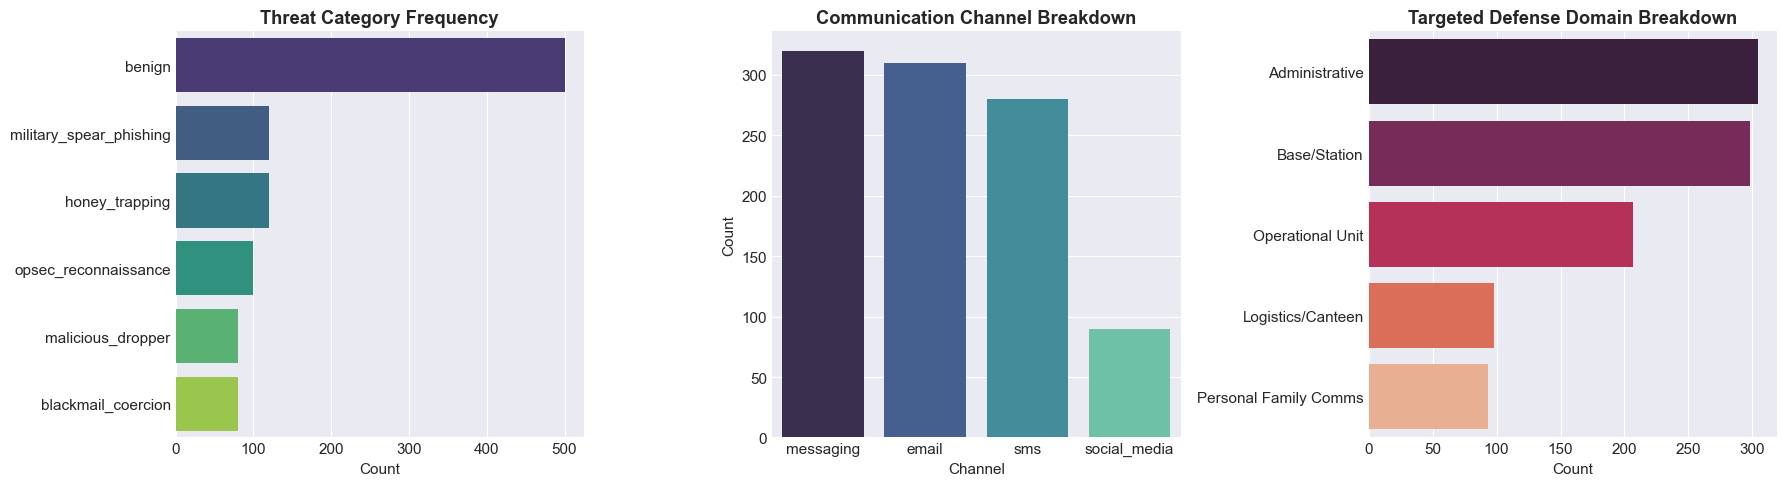

In [4]:
# Plotting Categorical Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Threat Categories
sns.countplot(data=df, y='threat_type', order=threat_counts.index, palette='viridis', ax=axes[0])
axes[0].set_title('Threat Category Frequency', fontweight='bold')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('')

# Plot 2: Delivery Channels
sns.countplot(data=df, x='channel', order=df['channel'].value_counts().index, palette='mako', ax=axes[1])
axes[1].set_title('Communication Channel Breakdown', fontweight='bold')
axes[1].set_xlabel('Channel')
axes[1].set_ylabel('Count')

# Plot 3: Defense Domains
sns.countplot(data=df, y='defense_domain', order=df['defense_domain'].value_counts().index, palette='rocket', ax=axes[2])
axes[2].set_title('Targeted Defense Domain Breakdown', fontweight='bold')
axes[2].set_xlabel('Count')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


## 4. Cross-Tabulation & Channel-Domain Threat Correlation
How are specific cyber threats distributed across communication channels and military operational domains?


=== Channel vs Threat Category Cross-Tabulation ===


threat_type,benign,blackmail_coercion,honey_trapping,malicious_dropper,military_spear_phishing,opsec_reconnaissance,All
channel,,,,,,,
email,163,27,0,32,50,38,310
messaging,163,17,64,48,0,28,320
sms,174,36,0,0,70,0,280
social_media,0,0,56,0,0,34,90
All,500,80,120,80,120,100,1000


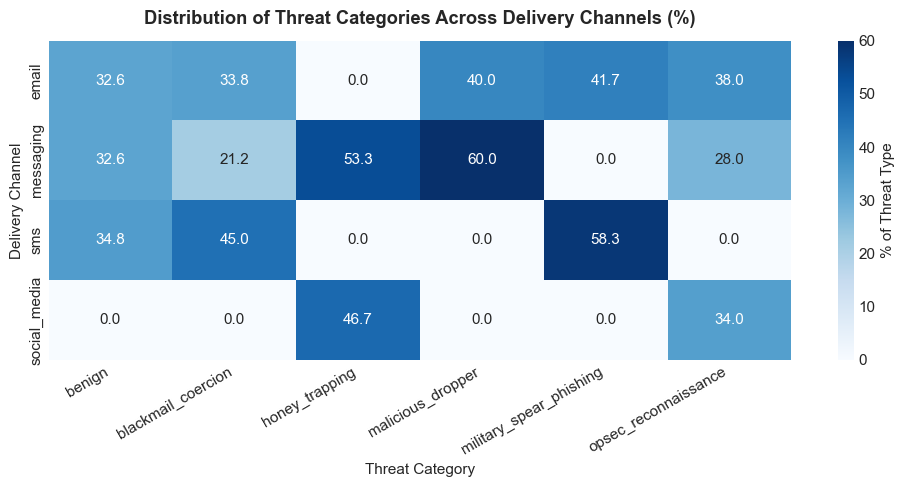

In [5]:
# Channel vs Threat Type Cross-Tabulation
channel_threat_crosstab = pd.crosstab(df['channel'], df['threat_type'], margins=True)
print("=== Channel vs Threat Category Cross-Tabulation ===")
display(channel_threat_crosstab)

# Heatmap visualization
plt.figure(figsize=(10, 5))
sns.heatmap(pd.crosstab(df['channel'], df['threat_type'], normalize='columns') * 100, 
            annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of Threat Type'})
plt.title('Distribution of Threat Categories Across Delivery Channels (%)', fontweight='bold', pad=12)
plt.xlabel('Threat Category')
plt.ylabel('Delivery Channel')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 5. Text Length & Lexical Statistics
Analyzing character counts and word counts across different threat categories to detect lexical patterns (e.g. are spear-phishing messages longer than honeytrap lures?).


char_length                 word_count             
                               mean   std  min  max       mean  std min max
threat_type                                                                
benign                        107.4   7.1   93  118       16.3  1.6  13  19
blackmail_coercion            184.0  22.9  148  210       28.2  5.9  22  36
honey_trapping                163.1  13.5  141  185       28.4  3.3  25  33
malicious_dropper             165.8  14.9  148  183       15.9  3.0  12  19
military_spear_phishing       169.9   6.0  161  179       17.8  3.5  15  26
opsec_reconnaissance          158.6  11.8  141  178       24.5  1.9  22  28

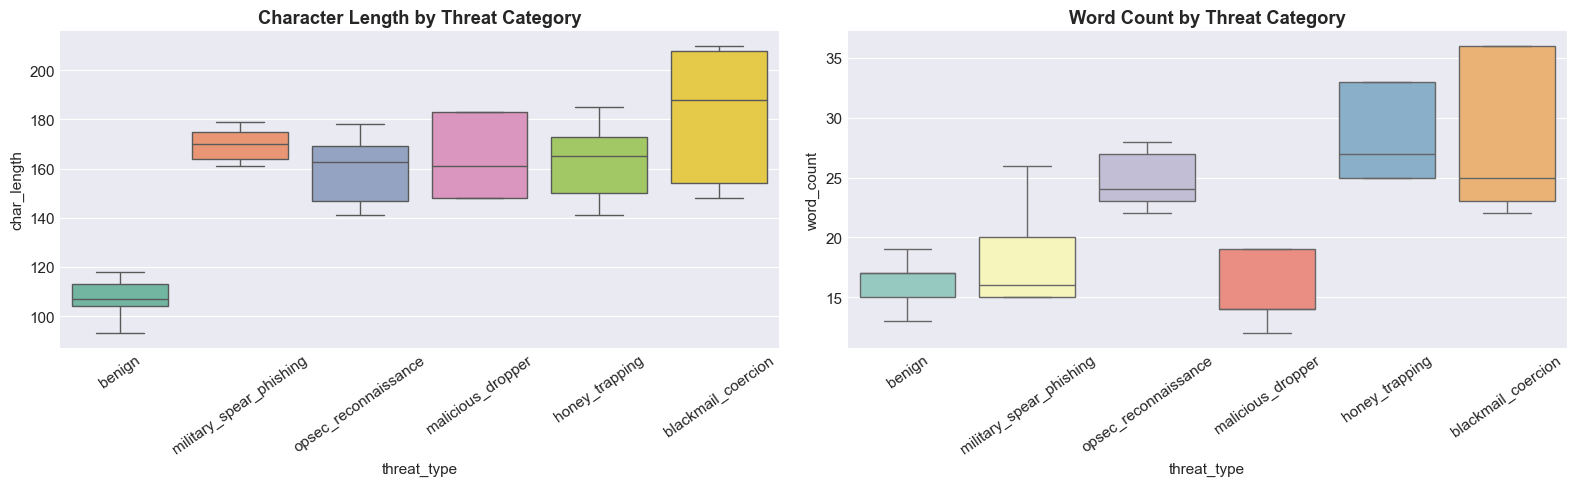

In [6]:
# Calculate text lengths
df['char_length'] = df['raw_text'].astype(str).str.len()
df['word_count'] = df['raw_text'].astype(str).apply(lambda x: len(x.split()))

# Summary statistics per threat type
length_summary = df.groupby('threat_type')[['char_length', 'word_count']].agg(['mean', 'std', 'min', 'max'])
display(length_summary.round(1))

# Boxplot of character lengths
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x='threat_type', y='char_length', palette='Set2', ax=axes[0])
axes[0].set_title('Character Length by Threat Category', fontweight='bold')
axes[0].tick_params(axis='x', rotation=35)

sns.boxplot(data=df, x='threat_type', y='word_count', palette='Set3', ax=axes[1])
axes[1].set_title('Word Count by Threat Category', fontweight='bold')
axes[1].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()


## 6. Text Cleaning & Token Normalization Pipeline
We build a dedicated text cleaner that:
1. Strips unnecessary whitespace and special formatting.
2. Identifies and tokenizes suspicious hyperlinks and domain extensions (`<URL>`).
3. Identifies and masks malicious dropper extensions (`.apk`, `.exe`, `.scr`, `.pdf.exe`) with `<PAYLOAD_EXT>`.
4. Normalizes text casing while preserving military terminology (SPARSH, BrahMos, JCO, etc.).


In [7]:
# Define Cleaning Patterns
URL_REGEX = re.compile(r'https?://\S+|www\.\S+|\b[a-zA-Z0-9.-]+\.(?:xyz|net|info|top|cc|online|work|in|org|com)\b', re.IGNORECASE)
DROPPER_REGEX = re.compile(r'\.(?:apk|exe|scr|docm|pdf\.exe|zip|bat|vbs|jar)', re.IGNORECASE)

def clean_defense_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    # Normalize whitespace
    cleaned = re.sub(r'[\r\n\t]+', ' ', text)
    # Mask URLs
    cleaned = URL_REGEX.sub('<URL>', cleaned)
    # Mask payload extensions
    cleaned = DROPPER_REGEX.sub('<PAYLOAD_EXT>', cleaned)
    # Normalize punctuation
    cleaned = re.sub(r'[^\w\s\<\>\-\.]', ' ', cleaned)
    # Collapse multiple spaces
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned.lower()

# Apply cleaning
df['cleaned_text'] = df['raw_text'].apply(clean_defense_text)

# Inspect before and after
print("=== Sample Text Preprocessing Comparison ===")
for i in [1, 3, 7, 8, 10]:
    print(f"\n[Raw {i}]:     {df['raw_text'].iloc[i]}")
    print(f"[Cleaned {i}]: {df['cleaned_text'].iloc[i]}")


=== Sample Text Preprocessing Comparison ===

[Raw 1]:     SPARSH Pensioner Portal Alert: Revised pension computation slip ready. Mandatory Aadhaar re-verification required immediately: http://sparsh-pension-defence-login.xyz/verify
[Cleaned 1]: sparsh pensioner portal alert revised pension computation slip ready. mandatory aadhaar re-verification required immediately <url>

[Raw 3]:     Hi, I work with a defense procurement research firm. What specific night-vision and thermal surveillance models are currently issued to Signals Corps at Siliguri?
[Cleaned 3]: hi i work with a defense procurement research firm. what specific night-vision and thermal surveillance models are currently issued to signals corps at siliguri

[Raw 7]:     Official Order: Revised Leave Rules 2026 issued by Military Secretary branch. Review attached movement roster and advisory doc: http://mil-orders-msbranch.net/Leave_Rules_2026.pdf.exe
[Cleaned 7]: official order revised leave rules 2026 issued by military se

## 7. Domain-Specific Cyber Threat Feature Engineering
We engineer targeted heuristics specifically designed for defence cybersecurity:
- `has_url`: Hyperlinks indicating phishing / credential harvesting.
- `has_dropper_ext`: Executable payloads (`.apk`, `.exe`, `.docm`).
- `has_opsec_terms`: Operational intelligence terms (corps, artillery, bunker, BrahMos, deployment, regiment).
- `has_coercion_terms`: Extortion & blackmail terms (court-martial, intimate, leak, archived records).
- `has_honeytrap_terms`: Social engineering bait (handsome, dashing, uniform, romantic, meetup).
- `has_urgency_terms`: Artificial deadlines (immediately, urgent, within X hours, mandatory).


In [8]:
# Define regex patterns for cyber threat indicators
OPSEC_REGEX = re.compile(r'\b(?:deployment|brigade|corps|artillery|radar|brahmos|regiment|bunker|ammunition|troop|lac|loc|border|patrolling|convoy|cantonment)\b', re.IGNORECASE)
COERCION_REGEX = re.compile(r'\b(?:court-martial|intimate|leak|blackmail|cooperate|archived|browsing records|private video|disclose|expose)\b', re.IGNORECASE)
HONEYTRAP_REGEX = re.compile(r'\b(?:handsome|dashing|sweetheart|babe|love|intimate|romantic|friendship|photo|selfie|meet up|attractive)\b', re.IGNORECASE)
URGENCY_REGEX = re.compile(r'\b(?:immediately|urgent|within \d+ hours|mandatory|suspended|locked|action required|final notice)\b', re.IGNORECASE)

# Extract binary feature indicators
df['has_url'] = df['raw_text'].apply(lambda x: int(bool(URL_REGEX.search(str(x)))))
df['has_dropper_ext'] = df['raw_text'].apply(lambda x: int(bool(DROPPER_REGEX.search(str(x)))))
df['has_opsec_terms'] = df['raw_text'].apply(lambda x: int(bool(OPSEC_REGEX.search(str(x)))))
df['has_coercion_terms'] = df['raw_text'].apply(lambda x: int(bool(COERCION_REGEX.search(str(x)))))
df['has_honeytrap_terms'] = df['raw_text'].apply(lambda x: int(bool(HONEYTRAP_REGEX.search(str(x)))))
df['has_urgency_terms'] = df['raw_text'].apply(lambda x: int(bool(URGENCY_REGEX.search(str(x)))))

feature_cols = ['char_length', 'word_count', 'has_url', 'has_dropper_ext', 'has_opsec_terms', 'has_coercion_terms', 'has_honeytrap_terms', 'has_urgency_terms']
display(df[feature_cols].describe().round(2))


,char_length,word_count,has_url,has_dropper_ext,has_opsec_terms,has_coercion_terms,has_honeytrap_terms,has_urgency_terms
count,1000.0,1000.00,1000.00,1000.0,1000.00,1000.00,1000.0,1000.00
mean,137.5,19.66,0.22,0.1,0.16,0.06,0.1,0.15
std,32.6,5.67,0.42,0.3,0.37,0.23,0.3,0.35
min,93.0,12.00,0.00,0.0,0.00,0.00,0.0,0.00
25%,107.0,15.00,0.00,0.0,0.00,0.00,0.0,0.00
50%,129.5,17.00,0.00,0.0,0.00,0.00,0.0,0.00
75%,168.0,23.25,0.00,0.0,0.00,0.00,0.0,0.00
max,210.0,36.00,1.00,1.0,1.00,1.00,1.0,1.00


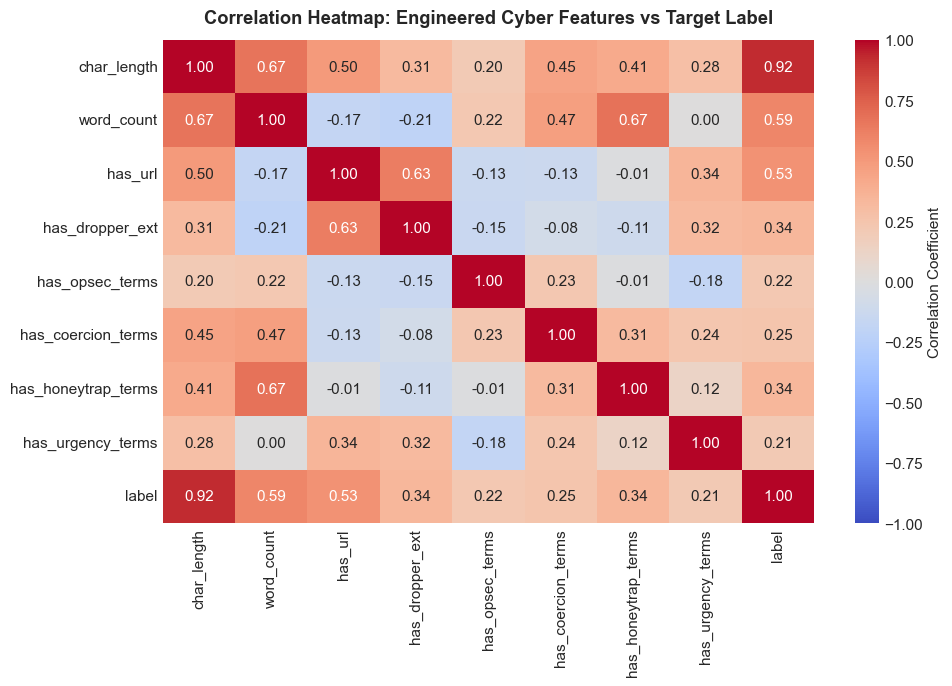

In [9]:
# Correlation Matrix of Engineered Features with Binary Label
corr = df[feature_cols + ['label']].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Heatmap: Engineered Cyber Features vs Target Label', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 8. Categorical & Target Encoding
We map the textual threat categories and categorical metadata to numerical representations:
- **`threat_type_encoded`**: 0: benign, 1: honey_trapping, 2: military_spear_phishing, 3: malicious_dropper, 4: blackmail_coercion, 5: opsec_reconnaissance
- **`channel_encoded`**: 0: messaging, 1: email, 2: sms, 3: social_media
- **`defense_domain_encoded`**: 0: Administrative, 1: Base/Station, 2: Operational Unit, 3: Logistics/Canteen, 4: Personal Family Comms


In [10]:
# Define Taxonomy Mappings
THREAT_MAP = {
    'benign': 0,
    'honey_trapping': 1,
    'military_spear_phishing': 2,
    'malicious_dropper': 3,
    'blackmail_coercion': 4,
    'opsec_reconnaissance': 5
}
CHANNEL_MAP = {'messaging': 0, 'email': 1, 'sms': 2, 'social_media': 3}
DOMAIN_MAP = {'Administrative': 0, 'Base/Station': 1, 'Operational Unit': 2, 'Logistics/Canteen': 3, 'Personal Family Comms': 4}

df['threat_type_encoded'] = df['threat_type'].map(THREAT_MAP)
df['channel_encoded'] = df['channel'].map(CHANNEL_MAP)
df['defense_domain_encoded'] = df['defense_domain'].map(DOMAIN_MAP)

print("=== Encoded Target Verification ===")
display(df[['threat_type', 'threat_type_encoded', 'channel', 'channel_encoded', 'defense_domain', 'defense_domain_encoded']].drop_duplicates())


=== Encoded Target Verification ===


,threat_type,threat_type_encoded,channel,channel_encoded,defense_domain,defense_domain_encoded
0,benign,0,email,1,Personal Family Comms,4
1,military_spear_phishing,2,email,1,Administrative,0
2,benign,0,sms,2,Personal Family Comms,4
3,opsec_reconnaissance,5,email,1,Operational Unit,2
5,benign,0,messaging,0,Operational Unit,2
6,benign,0,messaging,0,Base/Station,1
7,malicious_dropper,3,email,1,Administrative,0
8,honey_trapping,1,social_media,3,Base/Station,1
9,honey_trapping,1,messaging,0,Base/Station,1
10,opsec_reconnaissance,5,messaging,0,Operational Unit,2


## 9. TF-IDF Salient N-Gram Extraction per Threat Category
We extract the most influential unigrams and bigrams distinguishing each threat category from benign communication.


In [11]:
# Compute top TF-IDF n-grams per threat category
tfidf = TfidfVectorizer(max_features=1000, stop_words='english', ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df['cleaned_text'])
feature_names = np.array(tfidf.get_feature_names_out())

print("=== Top Salient Keywords per Threat Category ===")
for category, cat_id in THREAT_MAP.items():
    cat_mask = (df['threat_type'] == category).values
    if cat_mask.sum() == 0:
        continue
    mean_scores = X_tfidf[cat_mask].mean(axis=0).A1
    top_indices = mean_scores.argsort()[::-1][:6]
    top_terms = feature_names[top_indices]
    print(f"\n[{category.upper()}]:")
    print("   Keywords: " + ", ".join(top_terms))


=== Top Salient Keywords per Threat Category ===

[BENIGN]:
   Keywords: hrs, station, called, routine, inspection, morning

[HONEY_TRAPPING]:
   Keywords: currently stationed, stationed, post, share, currently, yesterday

[MILITARY_SPEAR_PHISHING]:
   Keywords: url, immediately url, immediately, service, organisation, pending

[MALICIOUS_DROPPER]:
   Keywords: zero, url, roster, click exploit, exploit, click

[BLACKMAIL_COERCION]:
   Keywords: chats, video, records chats, face, private browsing, martial proceedings

[OPSEC_RECONNAISSANCE]:
   Keywords: defense, border, clarify communication, vhf modern, vhf, communication


## 10. Export & Preprocessing Audit Summary
Finally, we export the fully preprocessed DataFrame to CSV and verify all columns.


In [12]:
# Export Cleaned Dataset
output_csv = 'cleaned_defense_threat_dataset.csv'
df.to_csv(output_csv, index=False, encoding='utf-8')
print(f"Cleaned dataset successfully exported to: {output_csv}")

print(f"\n=== Final Preprocessed DataFrame Audit ===")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print("Column List:")
for idx, col in enumerate(df.columns, 1):
    print(f"  {idx}. {col} ({df[col].dtype})")


Cleaned dataset successfully exported to: cleaned_defense_threat_dataset.csv

=== Final Preprocessed DataFrame Audit ===
Rows: 1000
Columns: 18
Column List:
  1. raw_text (object)
  2. channel (object)
  3. label (int64)
  4. threat_type (object)
  5. defense_domain (object)
  6. mitigation_first_aid (object)
  7. char_length (int64)
  8. word_count (int64)
  9. cleaned_text (object)
  10. has_url (int64)
  11. has_dropper_ext (int64)
  12. has_opsec_terms (int64)
  13. has_coercion_terms (int64)
  14. has_honeytrap_terms (int64)
  15. has_urgency_terms (int64)
  16. threat_type_encoded (int64)
  17. channel_encoded (int64)
  18. defense_domain_encoded (int64)
